# SPECTRA tutorial 1: tract profiles

This notebook builds 1D and 2D microstructure profiles for one bundle in Python, using the same functions that the `spectra_profile` command calls. 
It runs on `sample_data/profile/`: the left corticospinal tract (CST_L) of one control subject from the DIPY-processed PPMI derivatives, with the subject's FA map and the atlas bundle.

Equivalent command using SPECTRA CLI:
```bash
spectra_profile -rec CST_L__rec.trk -org CST_L__org.trk -ref CST_L__atlas.trk \
    -maps fa.nii.gz -profiles outputs/CST_L_fa -s 5 -r 5 -robust linear
```

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from dipy.io.image import load_nifti
from fury import actor, window

from spectra.utils.streamline import read_streamlines
from spectra.tractometry.parameterization import (
    get_grid_from_atlas, parameterize_bundle, prepare_bundle_pairs,
    buan_profile, grid_profile,
)
from spectra.viz.colors import alternating_colors, color_from_values, get_palette
from spectra.viz.viz_fury import get_cam_settings_fury
from spectra.utils.utils import setup_logging

setup_logging()

## 1. Load the sample data

Profiling needs three versions of the bundle:
- `rec`: the subject's bundle in atlas (MNI) space, used to assign points to grid cells.
- `org`: the same streamlines in the subject's native space, used to sample the scalar map.
- `atlas`: the atlas bundle, which defines the grid shared by all subjects.

In [2]:
DATA_DIR = Path('../sample_data/profile')
OUT_DIR  = DATA_DIR / 'outputs'
OUT_DIR.mkdir(exist_ok=True)

rec_bundle, _, _, _   = read_streamlines(str(DATA_DIR / 'CST_L__rec.trk'))
org_bundle, _, _, _   = read_streamlines(str(DATA_DIR / 'CST_L__org.trk'))
atlas_bundle, _, _, _ = read_streamlines(str(DATA_DIR / 'CST_L__atlas.trk'))
fa, fa_affine = load_nifti(DATA_DIR / 'fa.nii.gz')

print(f'Subject bundle: {len(rec_bundle)} streamlines')
print(f'Atlas bundle:   {len(atlas_bundle)} streamlines')
print(f'FA map:         {fa.shape}')

Subject bundle: 3337 streamlines
Atlas bundle:   2528 streamlines
FA map:         (116, 116, 72)


## 2. Build the grid on the atlas bundle

`get_grid_from_atlas` places a centroid along the atlas bundle (the along-tract axis, s) and a radial axis across it (r), then divides both into cells of about `s_len` × `r_len` mm. It returns the cell of every atlas point, and the three things needed to place any subject on the same grid: the centroid, the radial direction at each segment, and the radial bin edges.

In [3]:
atlas_s, atlas_r, centroid, u_vecs, r_edges, s_len, r_len = get_grid_from_atlas(
    atlas_bundle,
    s_len=5,
    r_len=5,
    use_robust_centroid=True,
    robust_method='linear',
)
ns = len(centroid)        # along-tract segments
nr = len(r_edges) - 1     # radial bins

print(f'Grid: {ns} x {nr} cells of {s_len:.1f} x {r_len:.1f} mm')

2026-10-18 11:08:14,255 [INFO] [root:parameterization.compute_robust_centroid]: (linear): extended centroid to 27 points (arc_length=136.5mm, s_len=5.00mm)
2026-10-18 11:08:14,603 [INFO] [root:parameterization.get_grid_from_atlas]: Created 2D signed parameterization in a (25, 15) grid (s_len=5.25mm, r_len=4.74mm)
Grid: 25 x 15 cells of 5.2 x 4.7 mm


## 3. Place the subject's bundle on the grid

- `prepare_bundle_pairs` resamples the native-space and atlas-space bundles so their points correspond one to one. 
- `parameterize_bundle` then gives each point its along-tract segment (`s_index`) and radial bin (`r_index`). `valid_mask` is False for points outside the atlas's radial range or in cells with too few points, and `counts` is the number of points per cell.

In [4]:
org_bundle, rec_bundle = prepare_bundle_pairs(org_bundle, rec_bundle, use_even_points=True)

s_index, r_index, s_dist, valid_mask, counts = parameterize_bundle(
    rec_bundle, centroid, u_vecs, r_edges
)

print(f'Points: {len(s_index)}, of which {valid_mask.mean():.1%} are in a valid cell')

2026-10-18 11:08:17,380 [INFO] [root:parameterization.parameterize_bundle]: Masked 212/375 bins with point threshold=50.0
Points: 416547, of which 99.9% are in a valid cell


## 4. Visualize the grid

Coloring each streamline point by its cell, with alternating colors along s and r, shows the grid as a checkerboard on the bundle. The helper below renders a bundle with [FURY](https://fury.gl/) and returns a snapshot. Set `INTERACTIVE = True` to also open a window you can rotate before each snapshot is taken (this needs a display).

In [5]:
INTERACTIVE = False

def render_bundle(bundle, colors, cam='Sagittal_L', size=(800, 800)):
    """Render a bundle with one color per point and return the image."""
    scene = window.Scene()
    scene.SetBackground(1, 1, 1)
    scene.add(actor.line(bundle, colors=np.asarray(colors), fake_tube=True, linewidth=4))
    scene.set_camera(**get_cam_settings_fury(cam))
    scene.reset_camera()
    if INTERACTIVE:
        window.show(scene, size=size)
    return window.snapshot(scene, size=size, offscreen=True)

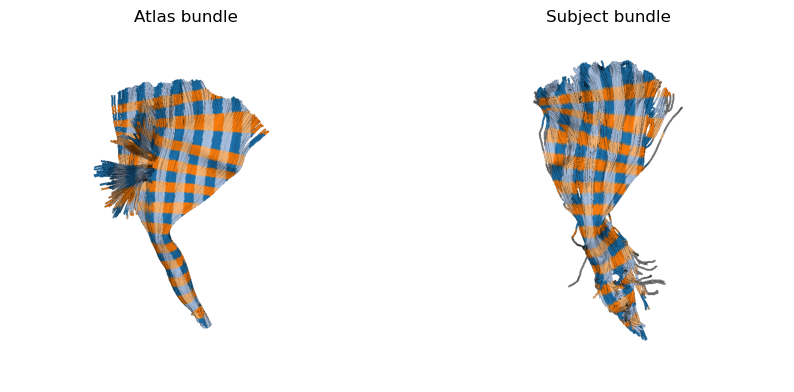

In [6]:
# Two color pairs that alternate along s; within each pair the colors alternate along r
checker = [get_palette('tab20', 0, 2), get_palette('tab20', 2, 4)]

img_atlas   = render_bundle(atlas_bundle, alternating_colors(atlas_s, atlas_r, checker))
img_subject = render_bundle(rec_bundle, alternating_colors(s_index, r_index, checker, valid_mask=valid_mask))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in zip(axes, [img_atlas, img_subject], ['Atlas bundle', 'Subject bundle']):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis('off')
plt.show()

The subject's points fall into the cells defined on the atlas, so the same cell covers the same part of the bundle in every subject. Points outside a valid cell are gray.

## 5. Compute the profiles

- `buan_profile` gives the 1D profile: one value per along-tract segment, a weighted mean over the points of the segment (BUAN).
- `grid_profile` gives the 2D profile: the mean over the valid points of each (s, r) cell.

Both sample the FA map at the native-space points. A value of 0 in a profile marks a cell with no data for this subject.

In [7]:
profile_1d = buan_profile(org_bundle, s_index, s_dist, ns, fa, fa_affine,
                          seg_counts=counts.sum(axis=1))
profile_2d = grid_profile(org_bundle, s_index, r_index, valid_mask, ns, nr, fa, fa_affine)

print('1D profile:', profile_1d.shape)
print('2D profile:', profile_2d.shape, f'({(profile_2d > 0).sum()} of {profile_2d.size} cells have data)')

# Uncomment the following to save in the same format as spectra_profile
# np.savez(
#     OUT_DIR / 'CST_L_fa.npz',
#     ns=ns, nr=nr, s_len=5, r_len=5,
#     profile_1d=profile_1d.astype(np.float32),
#     profile_2d=profile_2d.astype(np.float32),
# )

1D profile: (25,)
2D profile: (25, 15) (163 of 375 cells have data)


## 6. Visualize FA on the grid

First as flat plots: the 1D profile along the tract, and the 2D profile as an (s, r) grid. Cells with no data are left blank.

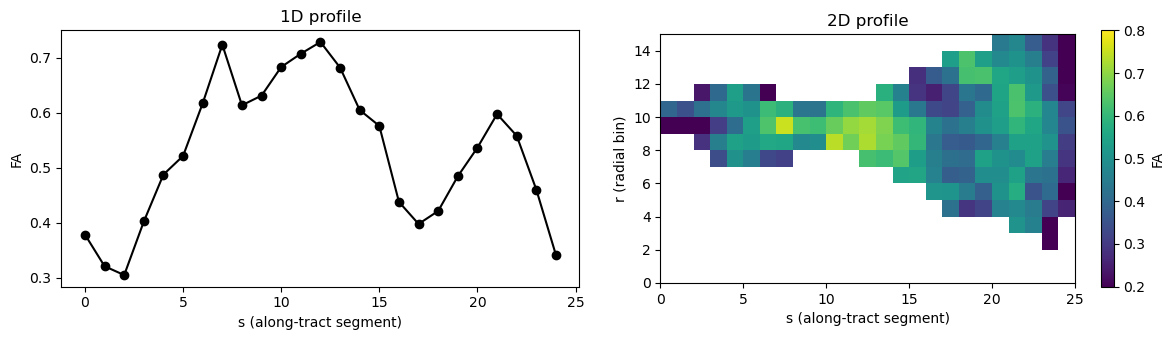

In [8]:
fa_grid = np.where(profile_2d > 0, profile_2d, np.nan)   # blank out cells with no data
VMIN, VMAX = 0.2, 0.8

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(profile_1d, 'o-', color='black')
axes[0].set_xlabel('s (along-tract segment)')
axes[0].set_ylabel('FA')
axes[0].set_title('1D profile')

mesh = axes[1].pcolormesh(np.ma.masked_invalid(fa_grid).T, cmap='viridis', vmin=VMIN, vmax=VMAX)
axes[1].set_aspect('equal')
axes[1].set_xlabel('s (along-tract segment)')
axes[1].set_ylabel('r (radial bin)')
axes[1].set_title('2D profile')
fig.colorbar(mesh, ax=axes[1], label='FA')

fig.tight_layout()
plt.show()

Then on the bundle: `color_from_values` gives every streamline point the value of its grid cell, so the bundle is painted with the 2D profile.

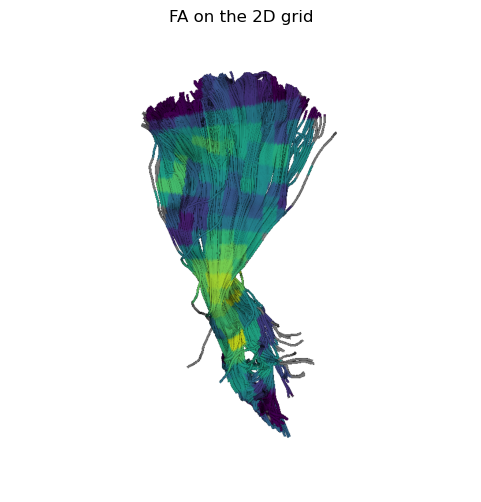

In [9]:
fa_colors = color_from_values(fa_grid, s_index, r_index, valid_mask=valid_mask,
                              cmap='viridis', vmin=VMIN, vmax=VMAX)
img_fa = render_bundle(rec_bundle, fa_colors)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_fa)
ax.set_title('FA on the 2D grid')
ax.axis('off')
plt.show()